# Queue throughput by buffer size

Throughput is calculated from the benchmark timestamps as `2^24 / (EndTimestamp - StartTimestamp)`. Each point is the mean across the available runs for that queue variant and buffer size.

In [17]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import pandas as pd

In [18]:
operations = 2**23
base_filename = "latency_throughput_buffer_"

result_root = Path("results")
if not result_root.exists():
    result_root = Path("/results")

if not result_root.exists():
    raise FileNotFoundError(f"Could not find benchmark results at {result_root.resolve()}")

csv_files = sorted(result_root.glob("*/run-*/" + base_filename + "*.csv"))
if not csv_files:
    raise FileNotFoundError(f"No benchmark CSV files found under {result_root.resolve()}")

In [19]:
metadata_pattern = re.compile(
    r"StartTimestamp=(?P<start>[0-9.]+)\s+"
    r"EndTimestamp=(?P<end>[0-9.]+)"
)
records = []

for file in csv_files:
    with file.open() as handle:
        metadata = handle.readline().strip()

    match = metadata_pattern.search(metadata)
    if match is None:
        raise ValueError(f"Missing benchmark timestamps in {file}")

    start = float(match.group("start"))
    end = float(match.group("end"))
    elapsed = end - start
    if elapsed <= 0:
        raise ValueError(f"Non-positive benchmark duration in {file}: {elapsed}")

    variant = file.parts[-3]
    ordering = "seq-cst" if variant.endswith("-seq_cst") else "acq-rel"
    family = variant.removesuffix("-seq_cst")
    buffer_size = int(file.stem.removeprefix(base_filename))
    run = file.parts[-2]

    records.append(
        {
            "variant": variant,
            "family": family,
            "ordering": ordering,
            "buffer_size": buffer_size,
            "run": run,
            "throughput": operations / elapsed,
        }
    )

# Create a table with one row per buffer size and one column per variant.
throughput_df = pd.DataFrame(records)

throughput_df.pivot_table(
    index="buffer_size",
    columns="variant",
    values="throughput",
    aggfunc="mean",
).sort_index()

throughput_df = pd.DataFrame(records)
throughput_df

,variant,family,ordering,buffer_size,run,throughput
0,0-naive,0-naive,acq-rel,1024,run-01,7.854690e+06
1,0-naive,0-naive,acq-rel,1048576,run-01,1.173743e+07
2,0-naive,0-naive,acq-rel,128,run-01,7.003430e+06
3,0-naive,0-naive,acq-rel,131072,run-01,1.002918e+07
4,0-naive,0-naive,acq-rel,16,run-01,6.941241e+06
...,...,...,...,...,...,...
2495,2-cached_indices_without_padding-seq_cst,2-cached_indices_without_padding,seq-cst,64,run-10,1.778257e+06
2496,2-cached_indices_without_padding-seq_cst,2-cached_indices_without_padding,seq-cst,65536,run-10,3.846870e+06
2497,2-cached_indices_without_padding-seq_cst,2-cached_indices_without_padding,seq-cst,8,run-10,2.441570e+06
2498,2-cached_indices_without_padding-seq_cst,2-cached_indices_without_padding,seq-cst,8192,run-10,3.546966e+06


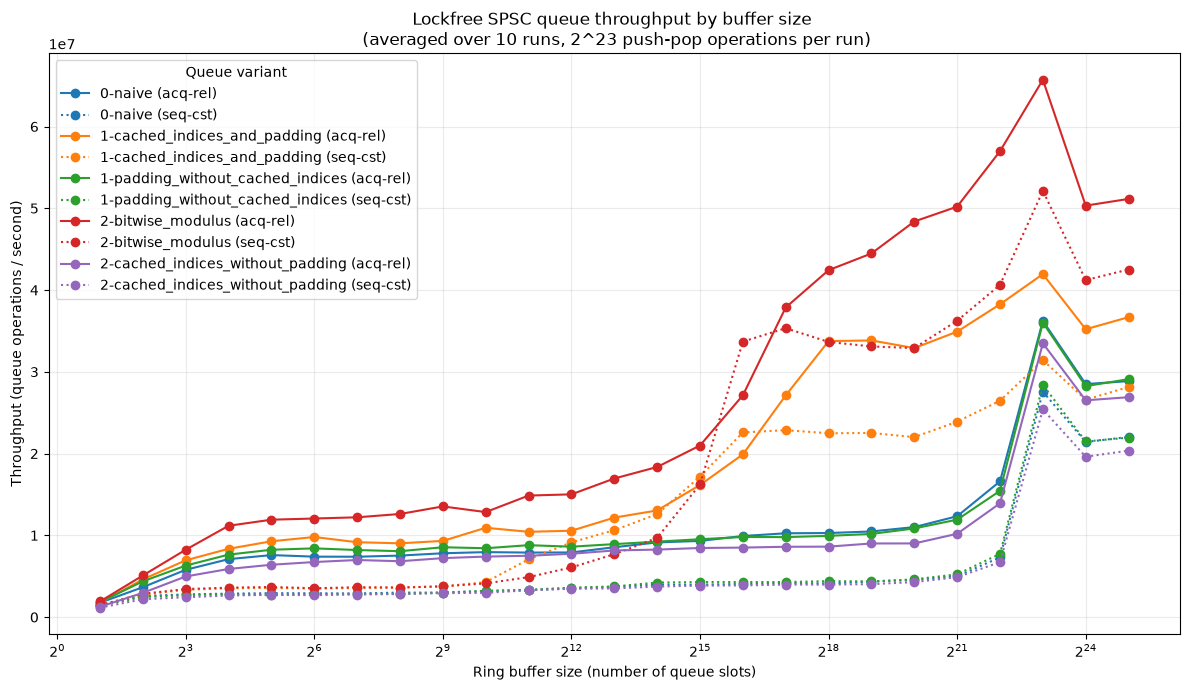

In [27]:
summary = (
    throughput_df.groupby(["family", "ordering", "buffer_size"], as_index=False)
    .agg(
        throughput=("throughput", "mean"),
        runs=("throughput", "size"),
    )
    .sort_values(["family", "ordering", "buffer_size"])
)

families = sorted(summary["family"].unique())
colors = dict(zip(families, plt.get_cmap("tab10").colors))
line_styles = {"acq-rel": "-", "seq-cst": ":"}

fig, ax = plt.subplots(figsize=(12, 7))
for (family, ordering), group in summary.groupby(["family", "ordering"]):
    group = group.sort_values("buffer_size")
    ax.plot(
        group["buffer_size"],
        group["throughput"],
        color=colors[family],
        linestyle=line_styles[ordering],
        marker="o",
        label=f"{family} ({ordering})",
    )

ax.set_xscale("log", base=2)
ax.set_xlabel("Ring buffer size (number of queue slots)")
ax.set_ylabel("Throughput (queue operations / second)")
ax.set_title("Lockfree SPSC queue throughput by buffer size \n (averaged over 10 runs, 2^23 push-pop operations per run)")
ax.grid(True, which="both", alpha=0.25)
ax.legend(title="Queue variant")
fig.tight_layout()
plt.show()